# Laboratorium 3: dane obrazowe, potok i własny zbiór kształtów

Autor: Adam Pastuszak

Kod do sprawozdania, samo sprawozdanie jest w osobnym pliku PDF

## 1. Importy

In [1]:
import colorsys
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
os.makedirs("figures", exist_ok=True)
print("PyTorch:", torch.__version__)

PyTorch: 2.15.0+cu132


## 2. Generowanie własnego zbioru: serce, strzałka i półksiężyc

In [2]:
ROOT = "dane"
KLASY = ["serce", "strzalka", "polksiezyc"]
N_NA_KLASE = 60
ROZMIAR = 96
rng = np.random.default_rng(42)


def wierzcholki(klasa, r):
    if klasa == "serce":
        t = np.linspace(0, 2 * np.pi, 80)
        x = 16 * np.sin(t) ** 3
        y = -(13 * np.cos(t) - 5 * np.cos(2 * t) - 2 * np.cos(3 * t)
              - np.cos(4 * t))
        return np.c_[x, y] * r / 17
    a, b = 0.22 * r, 0.55 * r
    return np.array([(-0.95 * r, -a), (0.2 * r, -a), (0.2 * r, -b), (r, 0),
                     (0.2 * r, b), (0.2 * r, a), (-0.95 * r, a)])


def kolor_hsv(h, s, v):
    return tuple(int(c * 255) for c in colorsys.hsv_to_rgb(h, s, v))


def generuj(klasa):
    r = rng.uniform(16, 30)
    obrot = rng.uniform(0, 360)
    odl, kier = rng.uniform(0, 46 - r), rng.uniform(0, 2 * np.pi)
    cx = ROZMIAR / 2 + odl * np.cos(kier)
    cy = ROZMIAR / 2 + odl * np.sin(kier)
    jasne_tlo = rng.random() < 0.5
    tlo = kolor_hsv(rng.random(), rng.uniform(0, 0.25),
                    rng.uniform(0.75, 0.95) if jasne_tlo
                    else rng.uniform(0.08, 0.3))
    wypelnienie = kolor_hsv(rng.random(), rng.uniform(0.6, 1.0),
                            rng.uniform(0.55, 1.0))
    t = np.radians(obrot)
    img = Image.new("RGB", (ROZMIAR, ROZMIAR), tlo)
    draw = ImageDraw.Draw(img)
    if klasa == "polksiezyc":
        draw.ellipse([cx - r, cy - r, cx + r, cy + r], fill=wypelnienie)
        ix, iy = cx + 0.45 * r * np.cos(t), cy + 0.45 * r * np.sin(t)
        draw.ellipse([ix - 0.8 * r, iy - 0.8 * r, ix + 0.8 * r,
                      iy + 0.8 * r], fill=tlo)
    else:
        rot = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
        pts = wierzcholki(klasa, r) @ rot.T + [cx, cy]
        draw.polygon([tuple(p) for p in pts], fill=wypelnienie)
    arr = np.asarray(img).astype(np.float32)
    arr += rng.normal(0, 8, arr.shape)  # lekki szum
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    return img, {"promien": round(r, 1), "obrot": round(obrot, 1),
                 "x": round(cx, 1), "y": round(cy, 1),
                 "tlo": "jasne" if jasne_tlo else "ciemne"}


rows = []
for klasa in KLASY:
    os.makedirs(f"{ROOT}/{klasa}", exist_ok=True)
    for i in range(N_NA_KLASE):
        img, par = generuj(klasa)
        plik = f"{klasa}/{klasa}_{i:03d}.png"
        img.save(f"{ROOT}/{plik}")
        rows.append({"plik": plik, "klasa": klasa, **par})
meta = pd.DataFrame(rows)
meta.to_csv("metadane.csv", index=False)
print(meta["klasa"].value_counts().to_dict())
print(meta.groupby("klasa")["tlo"].value_counts().unstack())
meta.head()

{'serce': 60, 'strzalka': 60, 'polksiezyc': 60}
tlo         ciemne  jasne
klasa                    
polksiezyc      28     32
serce           29     31
strzalka        29     31


,plik,klasa,promien,obrot,x,y,tlo
0,serce/serce_000.png,serce,26.8,158.0,42.7,32.4,jasne
1,serce/serce_001.png,serce,19.2,70.9,42.8,54.2,ciemne
2,serce/serce_002.png,serce,27.7,296.2,47.3,47.7,jasne
3,serce/serce_003.png,serce,28.7,338.7,45.3,57.5,ciemne
4,serce/serce_004.png,serce,27.1,2.1,50.9,49.8,jasne


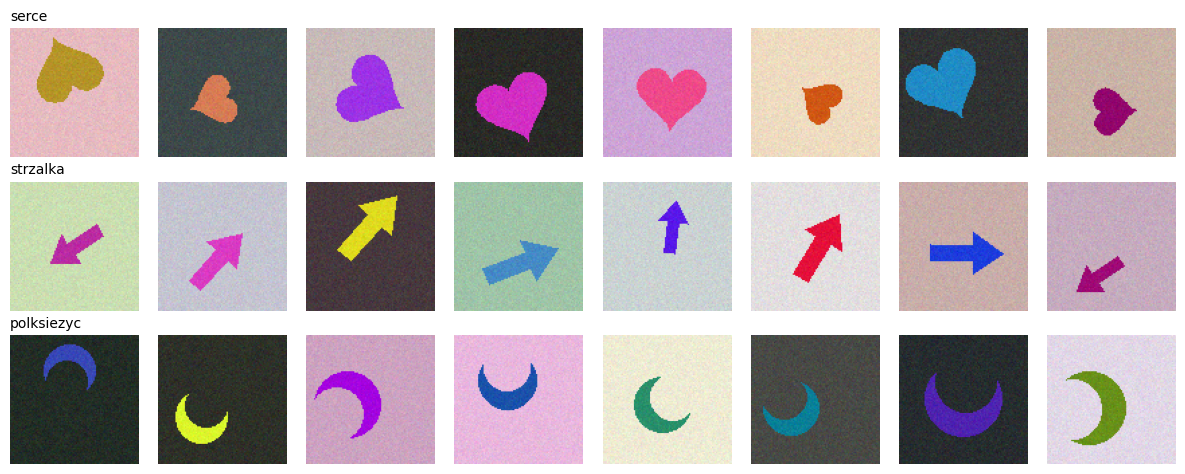

In [3]:
fig, axes = plt.subplots(3, 8, figsize=(12, 4.8))
for row, klasa in zip(axes, KLASY):
    for ax, plik in zip(row, meta[meta["klasa"] == klasa]["plik"][:8]):
        ax.imshow(Image.open(f"{ROOT}/{plik}"))
        ax.axis("off")
    row[0].set_title(klasa, loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("figures/przyklady.png", dpi=130)
plt.show()

## 3. Potok transformacji

In [4]:
IMG = 64

plain = datasets.ImageFolder(ROOT, transform=transforms.Compose([
    transforms.Resize((IMG, IMG)), transforms.ToTensor()]))
x_all = torch.stack([img for img, _ in plain])
MEAN = x_all.mean(dim=(0, 2, 3)).tolist()
STD = x_all.std(dim=(0, 2, 3)).tolist()
print("mean:", [round(m, 3) for m in MEAN],
      "| std:", [round(s, 3) for s in STD])

eval_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
train_tf = transforms.Compose([
    transforms.Resize((IMG, IMG)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3,
                           hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

mean: [0.498, 0.488, 0.49] | std: [0.321, 0.32, 0.32]


## 4. ImageFolder, DataLoader i statystyki

In [5]:
ds_eval = datasets.ImageFolder(ROOT, transform=eval_tf)
ds_train = datasets.ImageFolder(ROOT, transform=train_tf)
assert ds_eval.class_to_idx == ds_train.class_to_idx

counts = pd.Series(ds_eval.targets).map(
    {v: k for k, v in ds_eval.class_to_idx.items()}).value_counts()
x0, y0 = ds_eval[0]
print("Liczba klas:", len(ds_eval.classes))
print("class_to_idx:", ds_eval.class_to_idx)
print("Obrazy na klasę:", counts.to_dict(), "| razem:", len(ds_eval))
print("Rozmiar pliku:", Image.open(ds_eval.samples[0][0]).size,
      "| tensor po transformacji:", tuple(x0.shape), x0.dtype)

g = torch.Generator().manual_seed(0)
dl_train = DataLoader(ds_train, batch_size=16, shuffle=True, generator=g)
dl_eval = DataLoader(ds_eval, batch_size=16, shuffle=False)

xb, yb = next(iter(dl_train))
print("Paczka treningowa:", tuple(xb.shape), "| etykiety:", yb.tolist())
print(f"Zakres wartości po normalizacji: {xb.min():.2f} do {xb.max():.2f}")

Liczba klas: 3
class_to_idx: {'polksiezyc': 0, 'serce': 1, 'strzalka': 2}
Obrazy na klasę: {'polksiezyc': 60, 'serce': 60, 'strzalka': 60} | razem: 180
Rozmiar pliku: (96, 96) | tensor po transformacji: (3, 64, 64) torch.float32
Paczka treningowa: (16, 3, 64, 64) | etykiety: [2, 0, 0, 1, 2, 0, 1, 0, 0, 0, 2, 2, 2, 0, 2, 2]
Zakres wartości po normalizacji: -1.55 do 1.60


## 5. Siatka przykładów z paczki

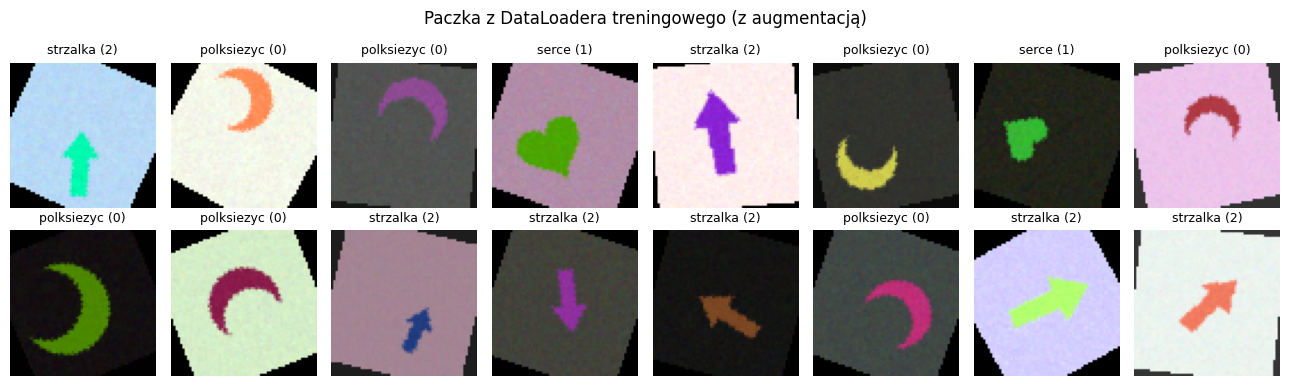

In [6]:
def denorm(t):
    m = torch.tensor(MEAN).view(3, 1, 1)
    s = torch.tensor(STD).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()


fig, axes = plt.subplots(2, 8, figsize=(13, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow(denorm(img))
    ax.set_title(f"{ds_train.classes[lb]} ({lb.item()})", fontsize=9)
    ax.axis("off")
plt.suptitle("Paczka z DataLoadera treningowego (z augmentacją)")
plt.tight_layout()
plt.savefig("figures/paczka.png", dpi=130)
plt.show()

## 6. Podgląd augmentacji na jednym obrazie

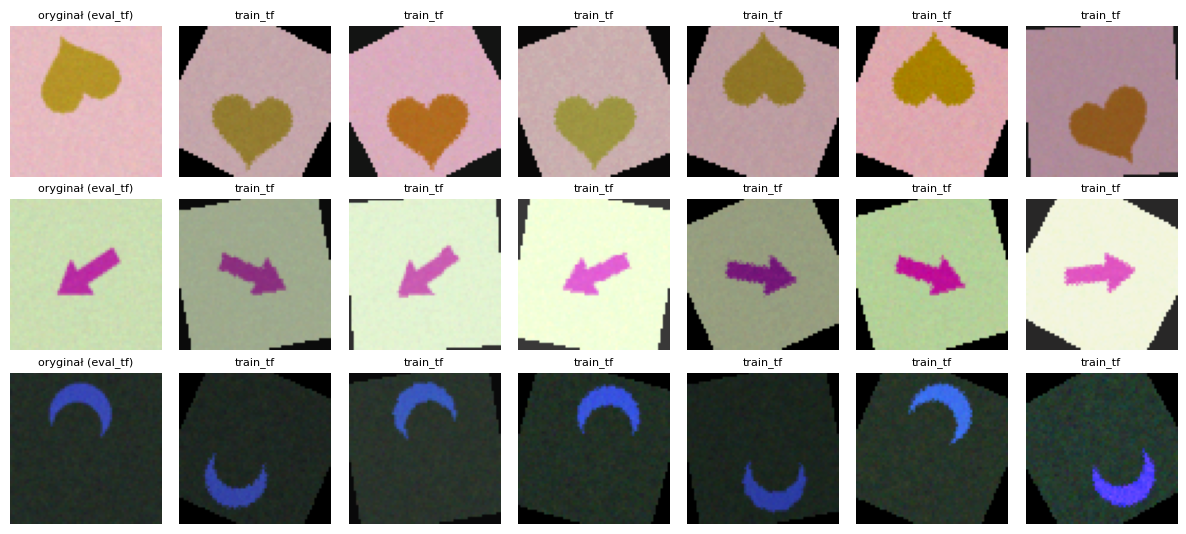

In [7]:
fig, axes = plt.subplots(len(KLASY), 7, figsize=(12, 5.4))
for row, klasa in zip(axes, KLASY):
    raw = Image.open(f"{ROOT}/{klasa}/{klasa}_000.png").convert("RGB")
    row[0].imshow(denorm(eval_tf(raw)))
    row[0].set_title("oryginał (eval_tf)", fontsize=8)
    for ax in row[1:]:
        ax.imshow(denorm(train_tf(raw)))
        ax.set_title("train_tf", fontsize=8)
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.savefig("figures/augmentacja.png", dpi=130)
plt.show()